# Gestión de memoria en FreeRTOS

<img src="./uso.png" width="1000" />

Definimos el tipo el tipo int8, 16, 32 para independizarnos de la arquitectura del sistema. 

### Asignación de memoria

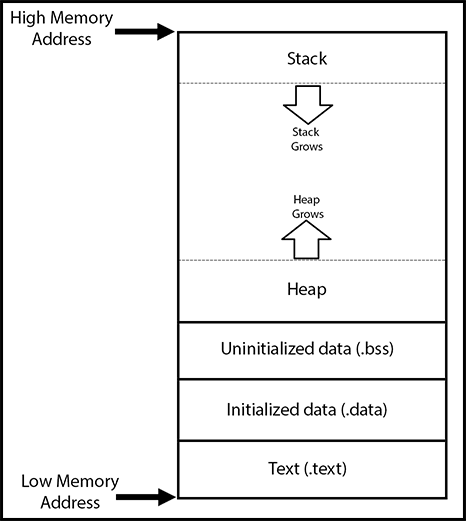

**TEXT :** Codigo -> Flash {Estático}

**BSS y DATA :** Datos Globales -> RAM {Estático}

**STACK y HEAP :** Datos -> RAM {Dinámico}

Las variables estáticas evolucionan con el tiempo de ejecución pero su tamaño es fijo y quedan rompiendo los huevos en el programa (nunca se liberan). Conviene trabajar con variables locales/automáticas. Estas se crean en el stack, las variables creadas con **malloc** se crean en el **HEAP**. 

Si queremos programar en C++ usando FreeRTOS, los objetos deben instanciarse en forma estática; no se puede usar **new**, **malloc**, etc. 


<img src="./uso2.png" width="1000" />


**pvPortMalloc()** y **pvPortFree()** son el malloc y el free porteados para FreeRTOS.

<img src="./dinamico.png" width="1000" />

Estas funciones de FreeRTOS toman memoria de manera dinámica (las marcadas de color azul), y son todas las relacionadas con la creación de timers, tareas, eventos, etc.

 <img src="./modelos.png" width="1000" />

 

Modelo Heap 2: borro (libero) una tarea y solo puede entrar una tarea con el mismo stack. Por convención las tareas tienen el mismo stack.

Modelo Heap 4: Une los bloques de memoria que se liberan. Apenas encuentra un hueco asigna memoria. 

<img src="./first fit.png" width="1000" />

<img src="./liberacion.png" width="1000" />

# Parte Práctica

. Usar vTaskDelay() ; no bloquea el programa

. Para sincronizar dos tareas, usamos semaforos utilizando el take y el give de forma cruzada (en la tarea 1 hacemos el give a la tarea 2 haciendo take a la propia tarea al comienzo y viceversa).

. Por ejemplo para encender y apagar un led con dos tareas. Una arranca tomada y la otra dada, en otro caso se bloquea el sistema.

. Para crear semaforos usamos xSemaphoreCreateBinary() la otra sigue estando para garantizar retrocompatibilidad. 